In [1]:
import sys
import os

sys.path.insert(0, os.path.abspath("."))
sys.path.append(os.path.abspath("../../../"))

In [2]:
from desc import set_device
set_device("gpu")

As mentioned in [DESC Documentation on performance tips](https://desc-docs.readthedocs.io/en/latest/performance_tips.html), one can use compilation cache directory to reduce the compilation overhead time. Uncomment the next code block to take advantage of the cache.

Note: One needs to create jax-caches folder manually.

In [3]:
import jax

jax.config.update("jax_compilation_cache_dir", "../jax-caches")
jax.config.update("jax_persistent_cache_min_entry_size_bytes", -1)
jax.config.update("jax_persistent_cache_min_compile_time_secs", 0)

In [4]:
import numpy as np
from desc.coils import (
    CoilSet,
    FourierPlanarCoil,
    MixedCoilSet,
    initialize_modular_coils,
    initialize_saddle_coils,
)
import desc.examples
from desc.equilibrium import Equilibrium
from desc.plotting import plot_2d, plot_3d, plot_coils, plot_comparison
from desc.grid import LinearGrid
from desc.objectives import (
    ObjectiveFunction,
    CoilCurvature,
    CoilLength,
    CoilTorsion,
    CoilSetLinkingNumber,
    CoilSetMinDistance,
    PlasmaCoilSetMinDistance,
    QuadraticFlux,
    ToroidalFlux,
    FixSumCoilCurrent,
    FixParameters,
)
from desc.optimize import Optimizer
from desc.integrals import compute_B_plasma
import time
import plotly.express as px
import plotly.io as pio
from desc.coils import CoilSet, FourierXYZCoil
from desc.io import load
# This ensures Plotly output works in multiple places:
# plotly_mimetype: VS Code notebook UI
# notebook: "Jupyter: Export to HTML" command in VS Code
# See https://plotly.com/python/renderers/#multiple-renderers
pio.renderers.default = "plotly_mimetype+notebook"

In [5]:
def compute_average_normalized_field(
    field, eq, vacuum=False, chunk_size=None, B_plasma_chunk_size=None
):
    if B_plasma_chunk_size is None:
        B_plasma_chunk_size = chunk_size
    grid = LinearGrid(M=80, N=80, NFP=eq.NFP)
    if vacuum:
        # we can avoid the expensive plasma contribution calculation if we
        # just pass in the surface instead of the Equilibrium!
        Bn, surf_coords = field.compute_Bnormal(
            eq.surface,
            eval_grid=grid,
            chunk_size=chunk_size,
            B_plasma_chunk_size=B_plasma_chunk_size,
        )
    else:
        Bn, surf_coords = field.compute_Bnormal(
            eq,
            eval_grid=grid,
            chunk_size=chunk_size,
            B_plasma_chunk_size=B_plasma_chunk_size,
        )
    normalizing_field_vec = field.compute_magnetic_field(surf_coords)
    if not vacuum:
        # add plasma field to the normalizing field
        normalizing_field_vec += compute_B_plasma(
            eq, eval_grid=grid, chunk_size=B_plasma_chunk_size
        )
    normalizing_field = np.mean(np.linalg.norm(normalizing_field_vec, axis=1))
    return np.mean(np.abs(Bn)) / normalizing_field


def plot_field_lines(field, eq):
    # for starting locations we'll pick positions on flux surfaces on the outboard midplane
    grid_trace = LinearGrid(rho=np.linspace(0, 1, 9))
    r0 = eq.compute("R", grid=grid_trace)["R"]
    z0 = eq.compute("Z", grid=grid_trace)["Z"]
    fig, ax = desc.plotting.plot_surfaces(eq)
    fig, ax = desc.plotting.poincare_plot(
        field,
        r0,
        z0,
        NFP=eq.NFP,
        ax=ax,
        color="k",
        size=1,
    )
    return fig, ax

In [6]:
coilset = CoilSet.load("NFP3_coilset_36_coils_smoother_Bn_0p03_N5.h5")
plot_coils(coilset)
#coilset[0]

In [7]:
from desc.vmec import VMECIO
#eq = Equilibrium.load("eq_NFP3_A+10.0_tor+0.0_mr+0.30_shift+0.00_wd+0.00_elong+1.50_wellwt+2.0_vacuum_final2_resolve.h5")
eq = Equilibrium.load("eq_NFP3_A+10.0_tor+0.0_mr+0.30_shift+0.00_wd+0.00_elong+1.50_wellwt+2.0_vacuum_08_resolve.h5")

#eq_NFP2_A+8.0_tor+0.1_mr+0.10_shift+0.00_wd-0.05_elong+2.00_wellwt+2.0_vacuum_final2.h5
# Equilibrium is only used to get a good guess for starting points used for fieldline tracing
# If you want to use the eq object to calculate accurate physics quantities, you need to eq.solve the equilibrium.

In [8]:
coilset = CoilSet.from_symmetry(
                       coilset,
                       NFP=coilset.NFP,
                       sym=coilset.sym,
                       check_intersection=True,
                   )

# --- NFP=3 split into 3 equal toroidal chunks, same slice-format as NFP=2 case ---
nfp = 3
ncoils = len(coilset)
n_per = ncoils // nfp
i0 = n_per // 2  # analogous to your NFP=2 "start in the middle" trick

coilset1 = MixedCoilSet(coilset[i0 : i0 + n_per])
coilset2 = MixedCoilSet(coilset[i0 + n_per : i0 + 2 * n_per])
coilset3 = MixedCoilSet([coilset[i0 + 2 * n_per :], coilset[0 : i0]])

print("ncoils =", ncoils, "  n_per =", n_per)
print("len(coilset1), len(coilset2), len(coilset3) =", len(coilset1), len(coilset2), len(coilset3))

fig = plot_3d(eq, name="|B|")
fig = plot_coils(coilset1, fig=fig)
fig = plot_coils(coilset2, fig=fig)
fig = plot_coils(coilset3, fig=fig)
fig.show()


ncoils = 36   n_per = 12
len(coilset1), len(coilset2), len(coilset3) = 12 12 12


/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 3.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 3.



# L_over_R=0.0

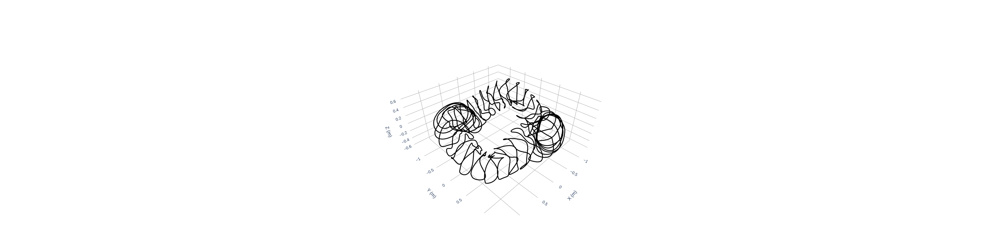

In [9]:
list_new = []
for i in range(len(coilset2)):
    data = coilset2[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + 0.0, data["Y"], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=6, current=coilset2[i].current))
    
coilset2_shifted = MixedCoilSet(list_new)

list_new = []
for i in range(len(coilset1)):
    data = coilset1[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] - 0.0, data["Y"], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=6, current=coilset1[i].current))
    
coilset1_shifted = MixedCoilSet(list_new)

# #plot_coils(MixedCoilSet(coilset2_shifted, coilset1))
# fig = plot_coils(coilset2_shifted)
# fig = plot_coils(coilset1_shifted, fig=fig)
# fig.show()

# data = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta =np.array([np.pi/2]), NFP=1, sym=False))
# data_center0 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([np.pi/2 - 0.1])))
# data_center1 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([np.pi/2 + 0.1])))
# normal = [data_center1["X"][0]-data_center0["X"][0]-0.5,data_center1["Y"][0]-data_center0["Y"][0],data_center1["Z"][0]-data_center0["Z"][0]]

# #I = -470000
# I = -100000
# r_0 = 0.57

# coilset3 = MixedCoilSet(
#                         #FourierPlanarCoil(I, center=[data["X"][0]+3/6, data_center0["Y"][0] , (3./3)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
#                         #FourierPlanarCoil(I, center=[data["X"][0]-3/6, data_center1["Y"][0] , (3./3)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
#                         #FourierPlanarCoil(I, center=[data["X"][0]+2.4/6, data_center0["Y"][0] , (2./2)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
#                         #FourierPlanarCoil(I, center=[data["X"][0]-2.4/6, data_center1["Y"][0] , (2./2)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
#                         FourierPlanarCoil(I, center=[data["X"][0]+1.2/6, data_center0["Y"][0] , (2./2)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
#                         FourierPlanarCoil(I, center=[data["X"][0]-1.2/6, data_center1["Y"][0] , (2./2)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
#                         FourierPlanarCoil(I, center=[data["X"][0], data["Y"][0] , 0.0*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
# )
# #print(data_center0["Y"][0]-data["Y"][0], data_center1["Y"][0]-data["Y"][0])

# data = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta =np.array([-1/2 * np.pi]), NFP=1, sym=False))
# data_center0 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([-1 * np.pi/2 + 0.1])))
# data_center1 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([-1 * np.pi/2 - 0.1])))
# normal = [data_center1["X"][0]-data_center0["X"][0]-0.5,data_center1["Y"][0]-data_center0["Y"][0],data_center1["Z"][0]-data_center0["Z"][0]]

# coilset4 = MixedCoilSet(#FourierPlanarCoil(-I, center=[data["X"][0]+3/6, data_center0["Y"][0] , (3./3)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
#                         #FourierPlanarCoil(-I, center=[data["X"][0]-3/6, data_center1["Y"][0] , (3./3)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
#                         #FourierPlanarCoil(-I, center=[data["X"][0]+2.4/6, data_center0["Y"][0] , (2./2)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
#                         #FourierPlanarCoil(-I, center=[data["X"][0]-2.4/6, data_center1["Y"][0] , (2./2)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
#                         FourierPlanarCoil(-I, center=[data["X"][0]+1.2/6, data_center0["Y"][0] , (2./2)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
#                         FourierPlanarCoil(-I, center=[data["X"][0]-1.2/6, data_center1["Y"][0] , (2./2)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
#                         FourierPlanarCoil(-I, center=[data["X"][0], data["Y"][0] , 0.0*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
# )

# #print(data_center0["Y"][0]-data["Y"][0], data_center1["Y"][0]-data["Y"][0])

# #fig = plot_coils(coilset2_shifted)
# #fig = plot_coils(coilset1_shifted, fig=fig)
# #fig = plot_coils(coilset3, fig=fig)
# #fig = plot_coils(coilset4, fig=fig)

#coilset_final0 = MixedCoilSet(coilset1_shifted, coilset2_shifted, coilset3, coilset4)
coilset_final0 = MixedCoilSet(coilset1_shifted, coilset2_shifted, coilset3)
#coilset_final0 = MixedCoilSet(coilset1_shifted)


fig = plot_coils(coilset_final0)
fig.show()

[1.0176563  1.01337603 1.00905192 1.00467833 1.00024638 0.99574443
 0.99115873 0.98647465 0.98167815 0.9767577  0.97170644 0.96652441]


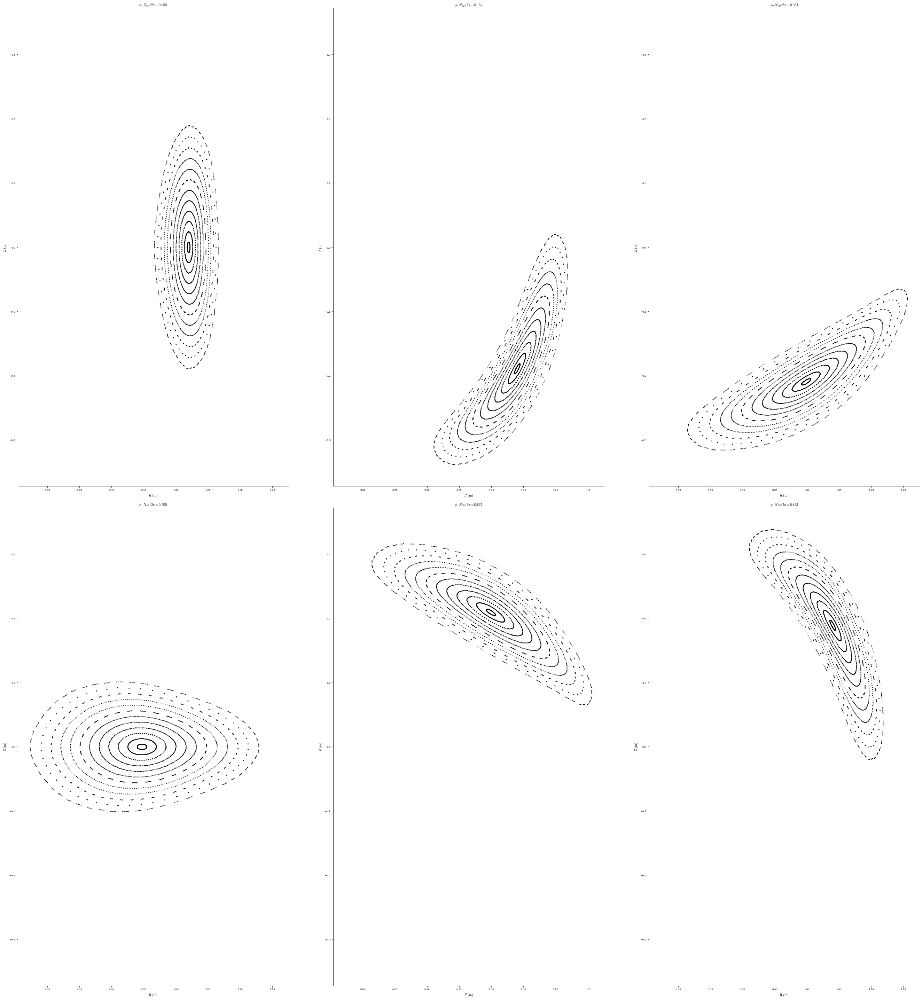

In [13]:
#plot_field_lines(surface_current_field, eq);
grid_trace = LinearGrid(rho=np.linspace(0.0, 1.0, 12))
#r0 = eq.compute("R", grid=grid_trace)["R"] + 1.095
r0 = eq.compute("R", grid=grid_trace)["R"] + 0.0051
z0 = eq.compute("Z", grid=grid_trace)["Z"]
print(r0)
#fig, ax = desc.plotting.plot_surfaces(eq, figsize=(40, 40))
fig, ax, data = desc.plotting.poincare_plot(
    coilset_final0,
    #coilset,
    r0,
    z0,
    ntransit=400,
    NFP=3,
    #ax=ax,
    color="k",
    size=1,
    return_data = True,
    bounds_R = (0.5, 2.0),
    bounds_Z = (-0.9, 0.9),
    figsize = (40, 40),
)
#np.savez("fieldline_trace_data_0p0-lowcur.npz", data=data)
#fig.show()

In [14]:
#np.savez("fieldline_trace_data_0p0-lowcur.npz", R=data["R"], Z=data["Z"])

# L_over_R=0.1

In [36]:
# --- L_over_R=0.5 (NFP=3) ---
L = 0.1

# chunk-center directions (0, 2pi/3, 4pi/3) -> shifts in XY
shift3 = np.array([ L * np.cos(0.0),          L * np.sin(0.0),          0.0])
shift1 = np.array([ L * np.cos(2*np.pi/3.0),  L * np.sin(2*np.pi/3.0),  0.0])
shift2 = np.array([ L * np.cos(4*np.pi/3.0),  L * np.sin(4*np.pi/3.0),  0.0])

# ---- shift coilset1 ----
list_new = []
for i in range(len(coilset1)):
    data = coilset1[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + shift1[0], data["Y"] + shift1[1], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=5, current=coilset1[i].current))
coilset1_shifted = MixedCoilSet(list_new)

# ---- shift coilset2 ----
list_new = []
for i in range(len(coilset2)):
    data = coilset2[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + shift2[0], data["Y"] + shift2[1], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=5, current=coilset2[i].current))
coilset2_shifted = MixedCoilSet(list_new)

# ---- shift coilset3 ----
list_new = []
for i in range(len(coilset3)):
    data = coilset3[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + shift3[0], data["Y"] + shift3[1], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=5, current=coilset3[i].current))
coilset3_shifted = MixedCoilSet(list_new)

fig = plot_coils(coilset1_shifted)
fig = plot_coils(coilset2_shifted, fig=fig)
fig = plot_coils(coilset3_shifted, fig=fig)
fig.show()
# ---- mirror coil ARRAYS: uniform spacing + minimum pitch (NO defs) ----
I = -660000
r_0 = 0.55

n_mirror = 9          # requested coils per gap
t_min = 0.5          # place between 15% and 85% of the bridge
t_max = 0.5
pitch_min = 0.22      # meters: if pitch smaller than this, reduce n automatically

mirror_list = []

# ========== GAP 1: coilset1_shifted -> coilset2_shifted ==========
dataA = coilset1_shifted[-1].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pA = np.array([np.mean(dataA["X"]), np.mean(dataA["Y"]), np.mean(dataA["Z"])])

dataB = coilset2_shifted[0].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pB = np.array([np.mean(dataB["X"]), np.mean(dataB["Y"]), np.mean(dataB["Z"])])

v = pB - pA
Lv = np.linalg.norm(v)
u = v / Lv

Lseg = (t_max - t_min) * Lv
pitch = Lseg / max(n_mirror - 1, 1)

n_use = n_mirror
if pitch < pitch_min:
    n_use = max(1, int(np.floor(Lseg / pitch_min)) + 1)

t_arr = np.linspace(t_min, t_max, n_use)
print("gap12: Lv=", float(Lv), " pitch=", float(Lseg/max(n_use-1,1)), " n_use=", n_use)

for t in t_arr:
    center = ((1.0 - t)*pA + t*pB).tolist()
    normal = v.tolist()
    mirror_list.append(FourierPlanarCoil(I, center=center, normal=normal, basis="xyz", r_n=r_0))

# ========== GAP 2: coilset2_shifted -> coilset3_shifted ==========
dataA = coilset2_shifted[-1].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pA = np.array([np.mean(dataA["X"]), np.mean(dataA["Y"]), np.mean(dataA["Z"])])

dataB = coilset3_shifted[0].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pB = np.array([np.mean(dataB["X"]), np.mean(dataB["Y"]), np.mean(dataB["Z"])])

v = pB - pA
Lv = np.linalg.norm(v)
u = v / Lv

Lseg = (t_max - t_min) * Lv
pitch = Lseg / max(n_mirror - 1, 1)

n_use = n_mirror
if pitch < pitch_min:
    n_use = max(1, int(np.floor(Lseg / pitch_min)) + 1)

t_arr = np.linspace(t_min, t_max, n_use)
print("gap23: Lv=", float(Lv), " pitch=", float(Lseg/max(n_use-1,1)), " n_use=", n_use)

for t in t_arr:
    center = ((1.0 - t)*pA + t*pB).tolist()
    normal = v.tolist()
    mirror_list.append(FourierPlanarCoil(I, center=center, normal=normal, basis="xyz", r_n=r_0))

# ========== GAP 3: coilset3_shifted -> coilset1_shifted (wrap) ==========
dataA = coilset3_shifted[-1].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pA = np.array([np.mean(dataA["X"]), np.mean(dataA["Y"]), np.mean(dataA["Z"])])

dataB = coilset1_shifted[0].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pB = np.array([np.mean(dataB["X"]), np.mean(dataB["Y"]), np.mean(dataB["Z"])])

v = pB - pA
Lv = np.linalg.norm(v)
u = v / Lv

Lseg = (t_max - t_min) * Lv
pitch = Lseg / max(n_mirror - 1, 1)

n_use = n_mirror
if pitch < pitch_min:
    n_use = max(1, int(np.floor(Lseg / pitch_min)) + 1)

t_arr = np.linspace(t_min, t_max, n_use)
print("gap31: Lv=", float(Lv), " pitch=", float(Lseg/max(n_use-1,1)), " n_use=", n_use)

for t in t_arr:
    center = ((1.0 - t)*pA + t*pB).tolist()
    normal = v.tolist()
    mirror_list.append(FourierPlanarCoil(I, center=center, normal=normal, basis="xyz", r_n=r_0))

coilset4 = MixedCoilSet(mirror_list)

coilset_final00 = MixedCoilSet(coilset1_shifted, coilset2_shifted, coilset3_shifted, coilset4)

fig = plot_coils(coilset1_shifted)
fig = plot_coils(coilset2_shifted, fig=fig)
fig = plot_coils(coilset3_shifted, fig=fig)
fig = plot_coils(coilset4, fig=fig)
fig.show()


gap12: Lv= 0.37232249561274083  pitch= 0.0  n_use= 1
gap23: Lv= 0.3723224956127406  pitch= 0.0  n_use= 1
gap31: Lv= 0.3723224956127405  pitch= 0.0  n_use= 1


[1.1335563  1.12691275 1.12015682 1.11325791 1.10617013 1.09884021
 1.0912208  1.0832882 ]


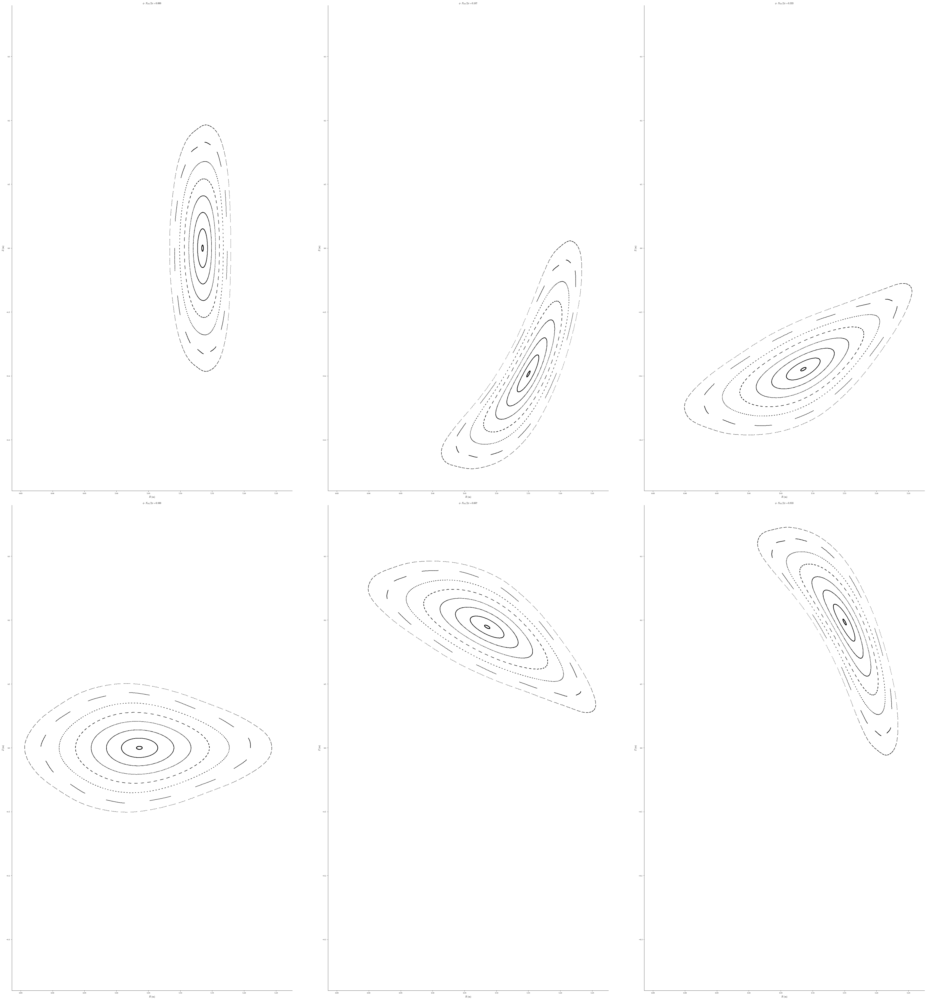

In [38]:
#plot_field_lines(surface_current_field, eq);
#grid_trace = LinearGrid(rho=np.concatenate((np.array([0., 0.25, 0.4, 0.5, 0.6]), np.linspace(0.68, 0.81, 5))))
grid_trace = LinearGrid(rho=np.linspace(0.0, 0.985, 8))
r0 = eq.compute("R", grid=grid_trace)["R"] + 0.121
z0 = eq.compute("Z", grid=grid_trace)["Z"]
print(r0)
#fig, ax = desc.plotting.plot_surfaces(eq, figsize=(40, 40))
fig, ax, data = desc.plotting.poincare_plot(
    coilset_final00,
    r0,
    z0,
    ntransit=600,
    NFP=3,
    #ax=ax,
    color="k",
    size=1,
    #phi=10,
    return_data = True,
    bounds_R = (0.5, 2.0),
    bounds_Z = (-1, 1),
    figsize = (60, 60),
)
#fig.show()

In [24]:
coilset_final00.save("SLNAMified_NFP3_A10p1_L_over_R_0p1_SLAM-A-lowcur.h5")

# L_over_R=0.5

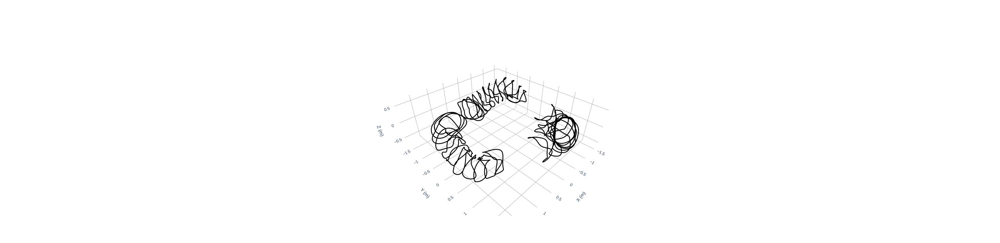

gap12: Lv= 1.052822504828546  pitch= 0.18424393834499553  n_use= 5
gap23: Lv= 1.052822504828546  pitch= 0.18424393834499553  n_use= 5
gap31: Lv= 1.0528225048285453  pitch= 0.18424393834499542  n_use= 5


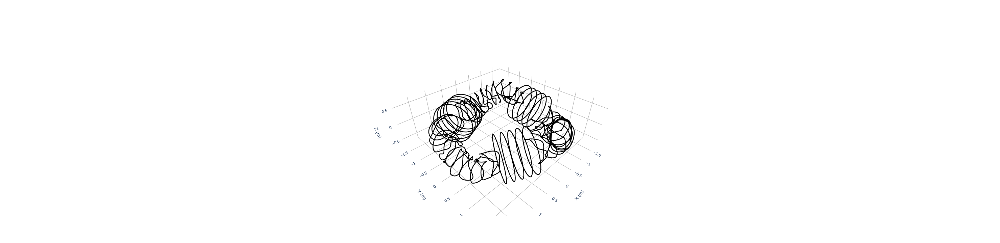

In [15]:
# --- L_over_R=0.5 (NFP=3) ---
L = 0.5

# chunk-center directions (0, 2pi/3, 4pi/3) -> shifts in XY
shift3 = np.array([ L * np.cos(0.0),          L * np.sin(0.0),          0.0])
shift1 = np.array([ L * np.cos(2*np.pi/3.0),  L * np.sin(2*np.pi/3.0),  0.0])
shift2 = np.array([ L * np.cos(4*np.pi/3.0),  L * np.sin(4*np.pi/3.0),  0.0])

# ---- shift coilset1 ----
list_new = []
for i in range(len(coilset1)):
    data = coilset1[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + shift1[0], data["Y"] + shift1[1], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=5, current=coilset1[i].current))
coilset1_shifted = MixedCoilSet(list_new)

# ---- shift coilset2 ----
list_new = []
for i in range(len(coilset2)):
    data = coilset2[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + shift2[0], data["Y"] + shift2[1], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=5, current=coilset2[i].current))
coilset2_shifted = MixedCoilSet(list_new)

# ---- shift coilset3 ----
list_new = []
for i in range(len(coilset3)):
    data = coilset3[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + shift3[0], data["Y"] + shift3[1], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=5, current=coilset3[i].current))
coilset3_shifted = MixedCoilSet(list_new)

fig = plot_coils(coilset1_shifted)
fig = plot_coils(coilset2_shifted, fig=fig)
fig = plot_coils(coilset3_shifted, fig=fig)
fig.show()
# ---- mirror coil ARRAYS: uniform spacing + minimum pitch (NO defs) ----
I = -610000
r_0 = 0.55

n_mirror = 9          # requested coils per gap
t_min = 0.15          # place between 15% and 85% of the bridge
t_max = 0.85
pitch_min = 0.18      # meters: if pitch smaller than this, reduce n automatically

mirror_list = []

# ========== GAP 1: coilset1_shifted -> coilset2_shifted ==========
dataA = coilset1_shifted[-1].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pA = np.array([np.mean(dataA["X"]), np.mean(dataA["Y"]), np.mean(dataA["Z"])])

dataB = coilset2_shifted[0].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pB = np.array([np.mean(dataB["X"]), np.mean(dataB["Y"]), np.mean(dataB["Z"])])

v = pB - pA
Lv = np.linalg.norm(v)
u = v / Lv

Lseg = (t_max - t_min) * Lv
pitch = Lseg / max(n_mirror - 1, 1)

n_use = n_mirror
if pitch < pitch_min:
    n_use = max(2, int(np.floor(Lseg / pitch_min)) + 1)

t_arr = np.linspace(t_min, t_max, n_use)
print("gap12: Lv=", float(Lv), " pitch=", float(Lseg/max(n_use-1,1)), " n_use=", n_use)

for t in t_arr:
    center = ((1.0 - t)*pA + t*pB).tolist()
    normal = v.tolist()
    mirror_list.append(FourierPlanarCoil(I, center=center, normal=normal, basis="xyz", r_n=r_0))

# ========== GAP 2: coilset2_shifted -> coilset3_shifted ==========
dataA = coilset2_shifted[-1].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pA = np.array([np.mean(dataA["X"]), np.mean(dataA["Y"]), np.mean(dataA["Z"])])

dataB = coilset3_shifted[0].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pB = np.array([np.mean(dataB["X"]), np.mean(dataB["Y"]), np.mean(dataB["Z"])])

v = pB - pA
Lv = np.linalg.norm(v)
u = v / Lv

Lseg = (t_max - t_min) * Lv
pitch = Lseg / max(n_mirror - 1, 1)

n_use = n_mirror
if pitch < pitch_min:
    n_use = max(2, int(np.floor(Lseg / pitch_min)) + 1)

t_arr = np.linspace(t_min, t_max, n_use)
print("gap23: Lv=", float(Lv), " pitch=", float(Lseg/max(n_use-1,1)), " n_use=", n_use)

for t in t_arr:
    center = ((1.0 - t)*pA + t*pB).tolist()
    normal = v.tolist()
    mirror_list.append(FourierPlanarCoil(I, center=center, normal=normal, basis="xyz", r_n=r_0))

# ========== GAP 3: coilset3_shifted -> coilset1_shifted (wrap) ==========
dataA = coilset3_shifted[-1].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pA = np.array([np.mean(dataA["X"]), np.mean(dataA["Y"]), np.mean(dataA["Z"])])

dataB = coilset1_shifted[0].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pB = np.array([np.mean(dataB["X"]), np.mean(dataB["Y"]), np.mean(dataB["Z"])])

v = pB - pA
Lv = np.linalg.norm(v)
u = v / Lv

Lseg = (t_max - t_min) * Lv
pitch = Lseg / max(n_mirror - 1, 1)

n_use = n_mirror
if pitch < pitch_min:
    n_use = max(2, int(np.floor(Lseg / pitch_min)) + 1)

t_arr = np.linspace(t_min, t_max, n_use)
print("gap31: Lv=", float(Lv), " pitch=", float(Lseg/max(n_use-1,1)), " n_use=", n_use)

for t in t_arr:
    center = ((1.0 - t)*pA + t*pB).tolist()
    normal = v.tolist()
    mirror_list.append(FourierPlanarCoil(I, center=center, normal=normal, basis="xyz", r_n=r_0))

coilset4 = MixedCoilSet(mirror_list)

coilset_final0 = MixedCoilSet(coilset1_shifted, coilset2_shifted, coilset3_shifted, coilset4)

fig = plot_coils(coilset1_shifted)
fig = plot_coils(coilset2_shifted, fig=fig)
fig = plot_coils(coilset3_shifted, fig=fig)
fig = plot_coils(coilset4, fig=fig)
fig.show()


[1.5435563  1.53927603 1.53495192 1.53057833 1.52614638 1.52164443
 1.51705873 1.51237465 1.50757815 1.5026577  1.49760644 1.49242441]


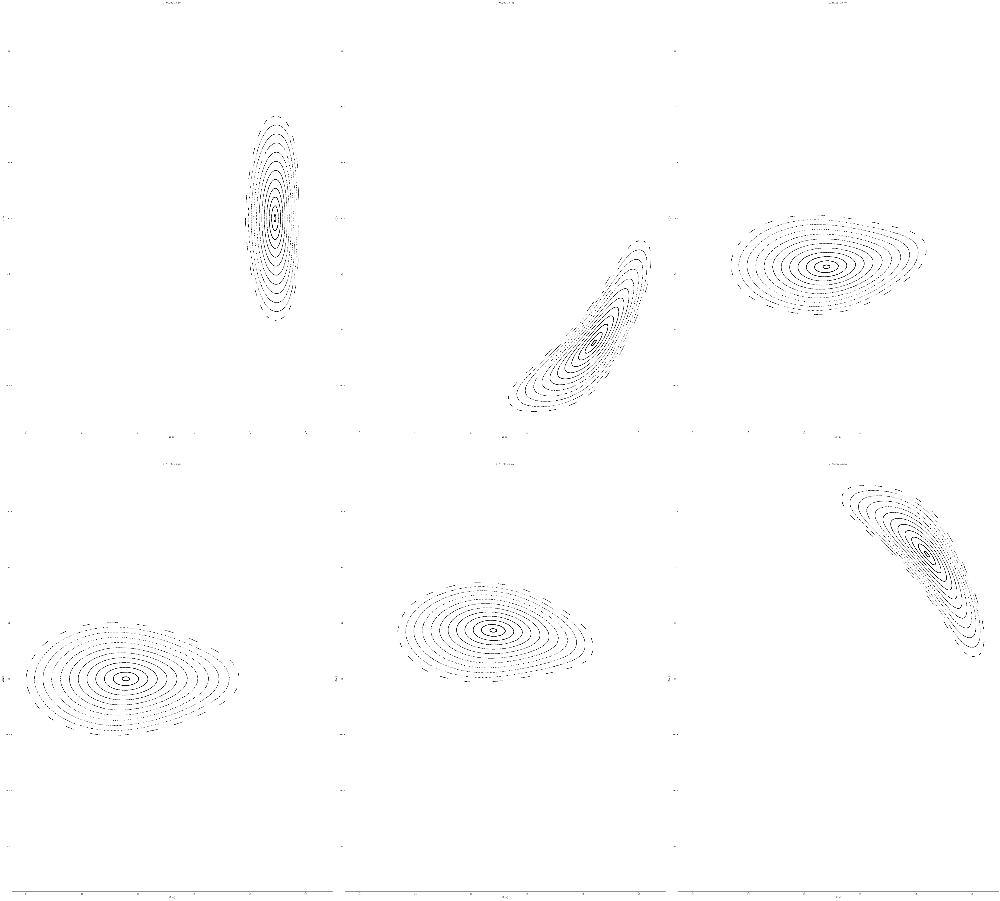

In [25]:
#plot_field_lines(surface_current_field, eq);
#grid_trace = LinearGrid(rho=np.concatenate((np.array([0., 0.25, 0.4, 0.5, 0.6]), np.linspace(0.68, 0.81, 5))))
grid_trace = LinearGrid(rho=np.linspace(0.0, 1.0, 12))
r0 = eq.compute("R", grid=grid_trace)["R"] + 0.531
z0 = eq.compute("Z", grid=grid_trace)["Z"]
print(r0)
#fig, ax = desc.plotting.plot_surfaces(eq, figsize=(40, 40))
fig, ax, data = desc.plotting.poincare_plot(
    coilset_final0,
    r0,
    z0,
    ntransit=600,
    NFP=3,
    #ax=ax,
    color="k",
    size=1,
    #phi=10,
    return_data = True,
    bounds_R = (0.5, 2.0),
    bounds_Z = (-1, 1),
    figsize = (60, 60),
)
np.savez("fieldline_trace_data_0p5-lowcur.npz", R=data["R"], Z=data["Z"])
#fig.show()

In [29]:
##print(eq.compute("R0/a")["R0/a"])
#coilset_final0.save("SLNAMified_NFP3_A10p1_L_over_R_0p5_SLAM-A-low.h5")

# L_over_R=1.0

In [18]:
# --- L_over_R=0.5 (NFP=3) ---
L = 1.0

# chunk-center directions (0, 2pi/3, 4pi/3) -> shifts in XY
shift3 = np.array([ L * np.cos(0.0),          L * np.sin(0.0),          0.0])
shift1 = np.array([ L * np.cos(2*np.pi/3.0),  L * np.sin(2*np.pi/3.0),  0.0])
shift2 = np.array([ L * np.cos(4*np.pi/3.0),  L * np.sin(4*np.pi/3.0),  0.0])

# ---- shift coilset1 ----
list_new = []
for i in range(len(coilset1)):
    data = coilset1[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + shift1[0], data["Y"] + shift1[1], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=5, current=coilset1[i].current))
coilset1_shifted = MixedCoilSet(list_new)

# ---- shift coilset2 ----
list_new = []
for i in range(len(coilset2)):
    data = coilset2[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + shift2[0], data["Y"] + shift2[1], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=5, current=coilset2[i].current))
coilset2_shifted = MixedCoilSet(list_new)

# ---- shift coilset3 ----
list_new = []
for i in range(len(coilset3)):
    data = coilset3[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + shift3[0], data["Y"] + shift3[1], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=5, current=coilset3[i].current))
coilset3_shifted = MixedCoilSet(list_new)

fig = plot_coils(coilset1_shifted)
fig = plot_coils(coilset2_shifted, fig=fig)
fig = plot_coils(coilset3_shifted, fig=fig)
fig.show()
# ---- mirror coil ARRAYS: uniform spacing + minimum pitch (NO defs) ----ajor hub f
I = -570000
r_0 = 0.55

n_mirror = 9          # requested coils per gap
t_min = 0.10          # place between 15% and 85% of the bridge
t_max = 0.90
pitch_min = 0.18      # meters: if pitch smaller than this, reduce n automatically

mirror_list = []

# ========== GAP 1: coilset1_shifted -> coilset2_shifted ==========
dataA = coilset1_shifted[-1].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pA = np.array([np.mean(dataA["X"]), np.mean(dataA["Y"]), np.mean(dataA["Z"])])

dataB = coilset2_shifted[0].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pB = np.array([np.mean(dataB["X"]), np.mean(dataB["Y"]), np.mean(dataB["Z"])])

v = pB - pA
Lv = np.linalg.norm(v)
u = v / Lv

Lseg = (t_max - t_min) * Lv
pitch = Lseg / max(n_mirror - 1, 1)

n_use = n_mirror
if pitch < pitch_min:
    n_use = max(2, int(np.floor(Lseg / pitch_min)) + 1)

t_arr = np.linspace(t_min, t_max, n_use)
print("gap12: Lv=", float(Lv), " pitch=", float(Lseg/max(n_use-1,1)), " n_use=", n_use)

for t in t_arr:
    center = ((1.0 - t)*pA + t*pB).tolist()
    normal = v.tolist()
    mirror_list.append(FourierPlanarCoil(I, center=center, normal=normal, basis="xyz", r_n=r_0))

# ========== GAP 2: coilset2_shifted -> coilset3_shifted ==========
dataA = coilset2_shifted[-1].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pA = np.array([np.mean(dataA["X"]), np.mean(dataA["Y"]), np.mean(dataA["Z"])])

dataB = coilset3_shifted[0].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pB = np.array([np.mean(dataB["X"]), np.mean(dataB["Y"]), np.mean(dataB["Z"])])

v = pB - pA
Lv = np.linalg.norm(v)
u = v / Lv

Lseg = (t_max - t_min) * Lv
pitch = Lseg / max(n_mirror - 1, 1)

n_use = n_mirror
if pitch < pitch_min:
    n_use = max(2, int(np.floor(Lseg / pitch_min)) + 1)

t_arr = np.linspace(t_min, t_max, n_use)
print("gap23: Lv=", float(Lv), " pitch=", float(Lseg/max(n_use-1,1)), " n_use=", n_use)

for t in t_arr:
    center = ((1.0 - t)*pA + t*pB).tolist()
    normal = v.tolist()
    mirror_list.append(FourierPlanarCoil(I, center=center, normal=normal, basis="xyz", r_n=r_0))

# ========== GAP 3: coilset3_shifted -> coilset1_shifted (wrap) ==========
dataA = coilset3_shifted[-1].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pA = np.array([np.mean(dataA["X"]), np.mean(dataA["Y"]), np.mean(dataA["Z"])])

dataB = coilset1_shifted[0].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pB = np.array([np.mean(dataB["X"]), np.mean(dataB["Y"]), np.mean(dataB["Z"])])

v = pB - pA
Lv = np.linalg.norm(v)
u = v / Lv

Lseg = (t_max - t_min) * Lv
pitch = Lseg / max(n_mirror - 1, 1)

n_use = n_mirror
if pitch < pitch_min:
    n_use = max(2, int(np.floor(Lseg / pitch_min)) + 1)

t_arr = np.linspace(t_min, t_max, n_use)
print("gap31: Lv=", float(Lv), " pitch=", float(Lseg/max(n_use-1,1)), " n_use=", n_use)

for t in t_arr:
    center = ((1.0 - t)*pA + t*pB).tolist()
    normal = v.tolist()
    mirror_list.append(FourierPlanarCoil(I, center=center, normal=normal, basis="xyz", r_n=r_0))

coilset4 = MixedCoilSet(mirror_list)

coilset_final1 = MixedCoilSet(coilset1_shifted, coilset2_shifted, coilset3_shifted, coilset4)

fig = plot_coils(coilset1_shifted)
fig = plot_coils(coilset2_shifted, fig=fig)
fig = plot_coils(coilset3_shifted, fig=fig)
fig = plot_coils(coilset4, fig=fig)
fig.show()


gap12: Lv= 1.9159068894628322  pitch= 0.19159068894628323  n_use= 9
gap23: Lv= 1.9159068894628326  pitch= 0.19159068894628328  n_use= 9
gap31: Lv= 1.9159068894628324  pitch= 0.19159068894628326  n_use= 9


[2.0475563  2.04327603 2.03895192 2.03457833 2.03014638 2.02564443
 2.02105873 2.01637465 2.01157815 2.0066577  2.00160644 1.99642441]


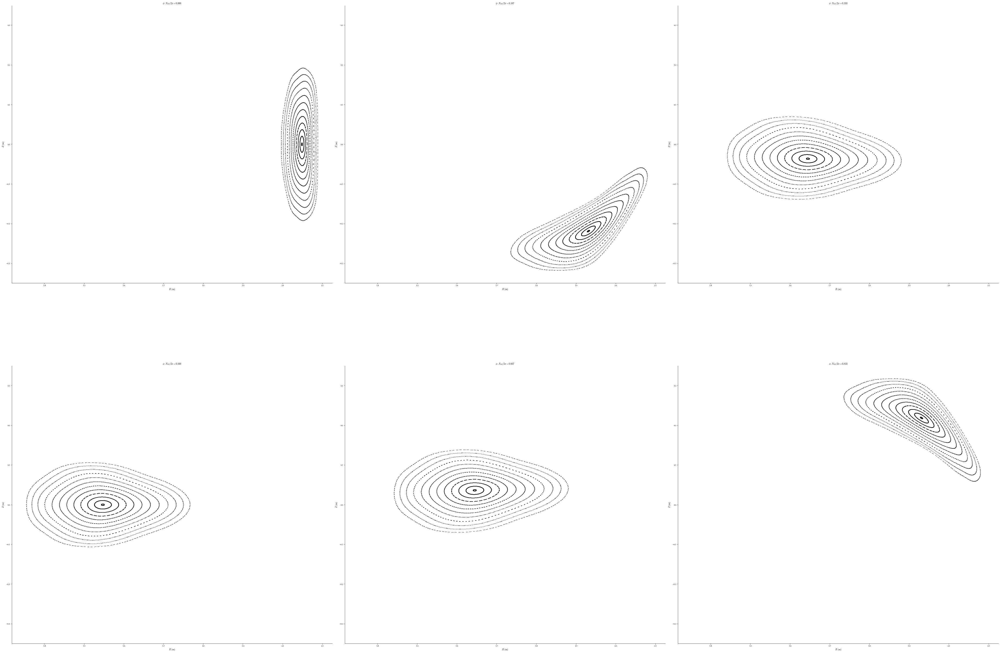

In [19]:
#plot_field_lines(surface_current_field, eq);
grid_trace = LinearGrid(rho=np.linspace(0.0, 1.00, 12))
#r0 = eq.compute("R", grid=grid_trace)["R"] + 1.084
r0 = eq.compute("R", grid=grid_trace)["R"] + 1.035
z0 = eq.compute("Z", grid=grid_trace)["Z"]
print(r0)
#fig, ax = desc.plotting.plot_surfaces(eq, figsize=(40, 40))
fig, ax, data = desc.plotting.poincare_plot(
    coilset_final1,
    r0,
    z0,
    ntransit=500,
    NFP=3,
    #ax=ax,
    color="k",
    size=1,
    return_data = True,
    bounds_R = (0.3, 2.6),
    bounds_Z = (-1, 1),
    figsize = (60, 60),
)
np.savez("fieldline_trace_data_1p0-lowcur.npz", R=data["R"], Z=data["Z"])
#fig.show()

In [20]:
#coilset_final1.save("SLNAMified_NFP3_A10p1_L_over_R_1p0_SLAM-A-low.h5")

# L_over_R = 1.5

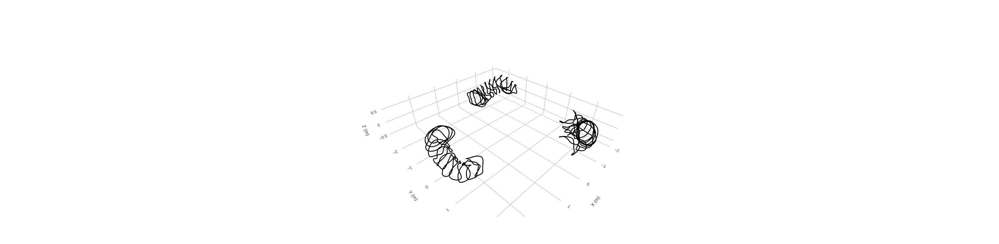

gap12: Lv= 2.7808205967859263  pitch= 0.1882401634747396  n_use= 14
gap23: Lv= 2.7808205967859263  pitch= 0.1882401634747396  n_use= 14
gap31: Lv= 2.7808205967859254  pitch= 0.18824016347473954  n_use= 14


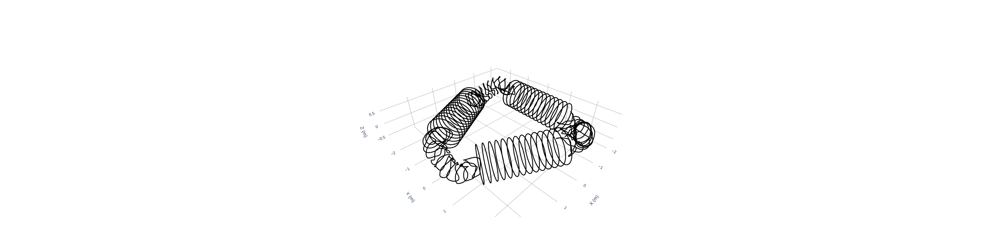

In [21]:
# --- L_over_R=0.5 (NFP=3) ---
L = 1.5

# chunk-center directions (0, 2pi/3, 4pi/3) -> shifts in XY
shift3 = np.array([ L * np.cos(0.0),          L * np.sin(0.0),          0.0])
shift1 = np.array([ L * np.cos(2*np.pi/3.0),  L * np.sin(2*np.pi/3.0),  0.0])
shift2 = np.array([ L * np.cos(4*np.pi/3.0),  L * np.sin(4*np.pi/3.0),  0.0])

# ---- shift coilset1 ----
list_new = []
for i in range(len(coilset1)):
    data = coilset1[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + shift1[0], data["Y"] + shift1[1], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=5, current=coilset1[i].current))
coilset1_shifted = MixedCoilSet(list_new)

# ---- shift coilset2 ----
list_new = []
for i in range(len(coilset2)):
    data = coilset2[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + shift2[0], data["Y"] + shift2[1], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=5, current=coilset2[i].current))
coilset2_shifted = MixedCoilSet(list_new)

# ---- shift coilset3 ----
list_new = []
for i in range(len(coilset3)):
    data = coilset3[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + shift3[0], data["Y"] + shift3[1], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=5, current=coilset3[i].current))
coilset3_shifted = MixedCoilSet(list_new)

fig = plot_coils(coilset1_shifted)
fig = plot_coils(coilset2_shifted, fig=fig)
fig = plot_coils(coilset3_shifted, fig=fig)
fig.show()
# ---- mirror coil ARRAYS: uniform spacing + minimum pitch (NO defs) ----
I = -550000
r_0 = 0.55

n_mirror = 14          # requested coils per gap
t_min = 0.06          # place between 15% and 85% of the bridge
t_max = 0.94
pitch_min = 0.18      # meters: if pitch smaller than this, reduce n automatically

mirror_list = []

# ========== GAP 1: coilset1_shifted -> coilset2_shifted ==========
dataA = coilset1_shifted[-1].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pA = np.array([np.mean(dataA["X"]), np.mean(dataA["Y"]), np.mean(dataA["Z"])])

dataB = coilset2_shifted[0].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pB = np.array([np.mean(dataB["X"]), np.mean(dataB["Y"]), np.mean(dataB["Z"])])

v = pB - pA
Lv = np.linalg.norm(v)
u = v / Lv

Lseg = (t_max - t_min) * Lv
pitch = Lseg / max(n_mirror - 1, 1)

n_use = n_mirror
if pitch < pitch_min:
    n_use = max(2, int(np.floor(Lseg / pitch_min)) + 1)

t_arr = np.linspace(t_min, t_max, n_use)
print("gap12: Lv=", float(Lv), " pitch=", float(Lseg/max(n_use-1,1)), " n_use=", n_use)

for t in t_arr:
    center = ((1.0 - t)*pA + t*pB).tolist()
    normal = v.tolist()
    mirror_list.append(FourierPlanarCoil(I, center=center, normal=normal, basis="xyz", r_n=r_0))

# ========== GAP 2: coilset2_shifted -> coilset3_shifted ==========
dataA = coilset2_shifted[-1].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pA = np.array([np.mean(dataA["X"]), np.mean(dataA["Y"]), np.mean(dataA["Z"])])

dataB = coilset3_shifted[0].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pB = np.array([np.mean(dataB["X"]), np.mean(dataB["Y"]), np.mean(dataB["Z"])])

v = pB - pA
Lv = np.linalg.norm(v)
u = v / Lv

Lseg = (t_max - t_min) * Lv
pitch = Lseg / max(n_mirror - 1, 1)

n_use = n_mirror
if pitch < pitch_min:
    n_use = max(2, int(np.floor(Lseg / pitch_min)) + 1)

t_arr = np.linspace(t_min, t_max, n_use)
print("gap23: Lv=", float(Lv), " pitch=", float(Lseg/max(n_use-1,1)), " n_use=", n_use)

for t in t_arr:
    center = ((1.0 - t)*pA + t*pB).tolist()
    normal = v.tolist()
    mirror_list.append(FourierPlanarCoil(I, center=center, normal=normal, basis="xyz", r_n=r_0))

# ========== GAP 3: coilset3_shifted -> coilset1_shifted (wrap) ==========
dataA = coilset3_shifted[-1].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pA = np.array([np.mean(dataA["X"]), np.mean(dataA["Y"]), np.mean(dataA["Z"])])

dataB = coilset1_shifted[0].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pB = np.array([np.mean(dataB["X"]), np.mean(dataB["Y"]), np.mean(dataB["Z"])])

v = pB - pA
Lv = np.linalg.norm(v)
u = v / Lv

Lseg = (t_max - t_min) * Lv
pitch = Lseg / max(n_mirror - 1, 1)

n_use = n_mirror
if pitch < pitch_min:
    n_use = max(2, int(np.floor(Lseg / pitch_min)) + 1)

t_arr = np.linspace(t_min, t_max, n_use)
print("gap31: Lv=", float(Lv), " pitch=", float(Lseg/max(n_use-1,1)), " n_use=", n_use)

for t in t_arr:
    center = ((1.0 - t)*pA + t*pB).tolist()
    normal = v.tolist()
    mirror_list.append(FourierPlanarCoil(I, center=center, normal=normal, basis="xyz", r_n=r_0))

coilset4 = MixedCoilSet(mirror_list)

coilset_final2 = MixedCoilSet(coilset1_shifted, coilset2_shifted, coilset3_shifted, coilset4)

fig = plot_coils(coilset1_shifted)
fig = plot_coils(coilset2_shifted, fig=fig)
fig = plot_coils(coilset3_shifted, fig=fig)
fig = plot_coils(coilset4, fig=fig)
fig.show()


[2.5475563  2.54336205 2.53912579 2.53484229 2.53050335 2.52609815
 2.52161392 2.51703689 2.51235367 2.50755292 2.50262728 2.49757538]


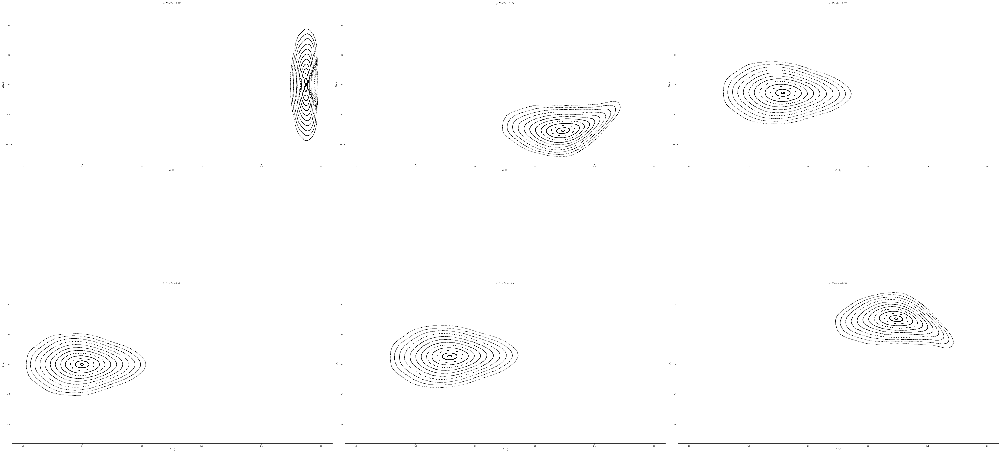

In [22]:
#plot_field_lines(surface_current_field, eq);
grid_trace = LinearGrid(rho=np.linspace(0.0, 0.98, 12))
#r0 = eq.compute("R", grid=grid_trace)["R"] + 1.084
r0 = eq.compute("R", grid=grid_trace)["R"] + 1.535
z0 = eq.compute("Z", grid=grid_trace)["Z"]
print(r0)
#fig, ax = desc.plotting.plot_surfaces(eq, figsize=(40, 40))
fig, ax, data = desc.plotting.poincare_plot(
    coilset_final2,
    r0,
    z0,
    ntransit=500,
    NFP=3,
    #ax=ax,
    color="k",
    size=1,
    return_data = True,
    bounds_R = (0.3, 3.6),
    bounds_Z = (-1, 1),
    figsize = (60, 60),
)
np.savez("fieldline_trace_data_1p5-lowcur.npz", R=data["R"], Z=data["Z"])

In [20]:
#coilset_final2.save("SLNAMified_NFP3_A10p1_L_over_R_1p5_SLAM-A-low.h5")

# L_over_R = 2

In [9]:
# --- L_over_R=0.5 (NFP=3) ---
L = 2.0

# chunk-center directions (0, 2pi/3, 4pi/3) -> shifts in XY
shift3 = np.array([ L * np.cos(0.0),          L * np.sin(0.0),          0.0])
shift1 = np.array([ L * np.cos(2*np.pi/3.0),  L * np.sin(2*np.pi/3.0),  0.0])
shift2 = np.array([ L * np.cos(4*np.pi/3.0),  L * np.sin(4*np.pi/3.0),  0.0])

# ---- shift coilset1 ----
list_new = []
for i in range(len(coilset1)):
    data = coilset1[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + shift1[0], data["Y"] + shift1[1], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=5, current=coilset1[i].current))
coilset1_shifted = MixedCoilSet(list_new)

# ---- shift coilset2 ----
list_new = []
for i in range(len(coilset2)):
    data = coilset2[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + shift2[0], data["Y"] + shift2[1], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=5, current=coilset2[i].current))
coilset2_shifted = MixedCoilSet(list_new)

# ---- shift coilset3 ----
list_new = []
for i in range(len(coilset3)):
    data = coilset3[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + shift3[0], data["Y"] + shift3[1], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=5, current=coilset3[i].current))
coilset3_shifted = MixedCoilSet(list_new)

fig = plot_coils(coilset1_shifted)
fig = plot_coils(coilset2_shifted, fig=fig)
fig = plot_coils(coilset3_shifted, fig=fig)
fig.show()
# ---- mirror coil ARRAYS: uniform spacing + minimum pitch (NO defs) ----
I = -590000
r_0 = 0.55

n_mirror = 18         # requested coils per gap
t_min = 0.04          # place between 15% and 85% of the bridge
t_max = 0.96
pitch_min = 0.18      # meters: if pitch smaller than this, reduce n automatically

mirror_list = []

# ========== GAP 1: coilset1_shifted -> coilset2_shifted ==========
dataA = coilset1_shifted[-1].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pA = np.array([np.mean(dataA["X"]), np.mean(dataA["Y"]), np.mean(dataA["Z"])])

dataB = coilset2_shifted[0].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pB = np.array([np.mean(dataB["X"]), np.mean(dataB["Y"]), np.mean(dataB["Z"])])

v = pB - pA
Lv = np.linalg.norm(v)
u = v / Lv

Lseg = (t_max - t_min) * Lv
pitch = Lseg / max(n_mirror - 1, 1)

n_use = n_mirror
if pitch < pitch_min:
    n_use = max(2, int(np.floor(Lseg / pitch_min)) + 1)

t_arr = np.linspace(t_min, t_max, n_use)
print("gap12: Lv=", float(Lv), " pitch=", float(Lseg/max(n_use-1,1)), " n_use=", n_use)

for t in t_arr:
    center = ((1.0 - t)*pA + t*pB).tolist()
    normal = v.tolist()
    mirror_list.append(FourierPlanarCoil(I, center=center, normal=normal, basis="xyz", r_n=r_0))

# ========== GAP 2: coilset2_shifted -> coilset3_shifted ==========
dataA = coilset2_shifted[-1].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pA = np.array([np.mean(dataA["X"]), np.mean(dataA["Y"]), np.mean(dataA["Z"])])

dataB = coilset3_shifted[0].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pB = np.array([np.mean(dataB["X"]), np.mean(dataB["Y"]), np.mean(dataB["Z"])])

v = pB - pA
Lv = np.linalg.norm(v)
u = v / Lv

Lseg = (t_max - t_min) * Lv
pitch = Lseg / max(n_mirror - 1, 1)

n_use = n_mirror
if pitch < pitch_min:
    n_use = max(2, int(np.floor(Lseg / pitch_min)) + 1)

t_arr = np.linspace(t_min, t_max, n_use)
print("gap23: Lv=", float(Lv), " pitch=", float(Lseg/max(n_use-1,1)), " n_use=", n_use)

for t in t_arr:
    center = ((1.0 - t)*pA + t*pB).tolist()
    normal = v.tolist()
    mirror_list.append(FourierPlanarCoil(I, center=center, normal=normal, basis="xyz", r_n=r_0))

# ========== GAP 3: coilset3_shifted -> coilset1_shifted (wrap) ==========
dataA = coilset3_shifted[-1].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pA = np.array([np.mean(dataA["X"]), np.mean(dataA["Y"]), np.mean(dataA["Z"])])

dataB = coilset1_shifted[0].compute(["X","Y","Z"], grid=LinearGrid(N=60))
pB = np.array([np.mean(dataB["X"]), np.mean(dataB["Y"]), np.mean(dataB["Z"])])

v = pB - pA
Lv = np.linalg.norm(v)
u = v / Lv

Lseg = (t_max - t_min) * Lv
pitch = Lseg / max(n_mirror - 1, 1)

n_use = n_mirror
if pitch < pitch_min:
    n_use = max(2, int(np.floor(Lseg / pitch_min)) + 1)

t_arr = np.linspace(t_min, t_max, n_use)
print("gap31: Lv=", float(Lv), " pitch=", float(Lseg/max(n_use-1,1)), " n_use=", n_use)

for t in t_arr:
    center = ((1.0 - t)*pA + t*pB).tolist()
    normal = v.tolist()
    mirror_list.append(FourierPlanarCoil(I, center=center, normal=normal, basis="xyz", r_n=r_0))

coilset4 = MixedCoilSet(mirror_list)

coilset_final3 = MixedCoilSet(coilset1_shifted, coilset2_shifted, coilset3_shifted, coilset4)

fig = plot_coils(coilset1_shifted)
fig = plot_coils(coilset2_shifted, fig=fig)
fig = plot_coils(coilset3_shifted, fig=fig)
fig = plot_coils(coilset4, fig=fig)
fig.show()


gap12: Lv= 3.646262082451908  pitch= 0.19732712446210324  n_use= 18
gap23: Lv= 3.6462620824519076  pitch= 0.1973271244621032  n_use= 18
gap31: Lv= 3.6462620824519076  pitch= 0.1973271244621032  n_use= 18


[3.0445563  3.04027603 3.03595192 3.03157833 3.02714638 3.02264443
 3.01805873 3.01337465 3.00857815 3.0036577  2.99860644 2.99342441]


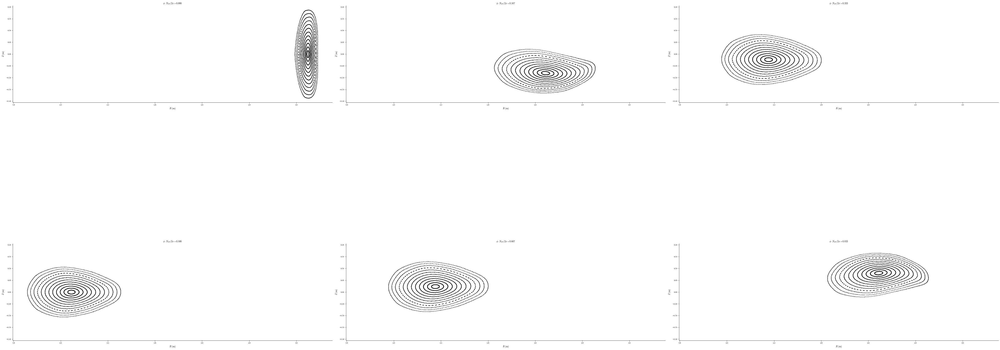

In [10]:
#plot_field_lines(surface_current_field, eq);
grid_trace = LinearGrid(rho=np.linspace(0.0, 1.0, 12))
r0 = eq.compute("R", grid=grid_trace)["R"] + 2.032
z0 = eq.compute("Z", grid=grid_trace)["Z"]
print(r0)
fig, ax, data = desc.plotting.poincare_plot(
    coilset_final3,
    r0,
    z0,
    ntransit=500,
    NFP=3,
    #ax=ax,
    color="k",
    size=1,
    return_data = True,
    bounds_R = (0.3, 4.6),
    bounds_Z = (-1, 1),
    figsize = (60, 60),
)
np.savez("fieldline_trace_data_2p0-lowcur.npz", R=data["R"], Z=data["Z"])

In [19]:
#coilset_final3.save("SLNAMified_NFP3_A10p1_L_over_R_2p0_SLAM-A-low.h5")